# Personalized Human Activity Recognition Using Smartphone Sensor Data

## Project Overview

This project investigates human activity recognition using smartphone accelerometer and gyroscope data.

A Logistic Regression model is used as a baseline classifier to recognize six daily activities. We then investigate whether personalization can improve recognition performance by incorporating a small amount of subject-specific data into the model.

### Research Question

> Can personalization improve human activity recognition for individual users?

### Main Objectives

- Build a baseline activity recognition model.
- Compare Logistic Regression and Random Forest.
- Analyze performance across individual subjects.
- Evaluate the effect of personalization.
- Investigate how the amount of personalization data affects model performance.

## Imports

We import the libraries required for data analysis, visualization, machine learning, and statistical evaluation.

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from scipy.stats import wilcoxon

## Data Loading
We load the training and test datasets from the Kaggle input directory.

In [55]:
train=pd.read_csv("/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones/train.csv")
test=pd.read_csv("/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones/test.csv")
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

Train Shape: (7352, 563)
Test Shape: (2947, 563)


## Data Exploration

We inspect the dataset structure, target variable, activity distribution, sample data, and data types.

In [56]:
print(train.columns[-1])

Activity


In [57]:
train["Activity"].value_counts()

Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

In [58]:
train.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [59]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(561), int64(1), object(1)
memory usage: 31.6+ MB


In [60]:
train.isnull().sum().sum()

np.int64(0)

## Activity Distribution

We visualize the distribution of the six activity classes in the training dataset.

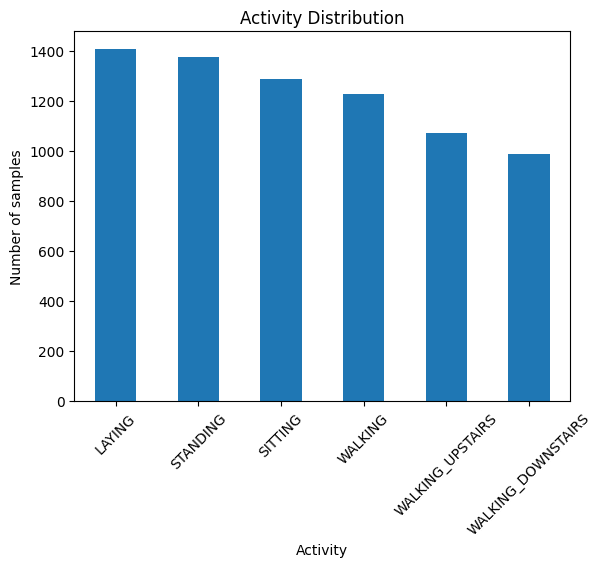

In [61]:
import matplotlib.pyplot as plt 
train["Activity"].value_counts().plot(kind="bar")
plt.title("Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of samples")
plt.xticks(rotation=45)
plt.show()

## Data Preparation

We separate the features from the target variable and exclude the subject ID from the model inputs.

In [62]:
x_train=train.drop(["Activity","subject"],axis=1)
y_train=train["Activity"]
x_test=test.drop(["Activity","subject"],axis=1)
y_test=test["Activity"]

print("x_train:",x_train.shape)
print("y_train:",y_train.shape)
print("x_test:",x_test.shape)
print("y_test:",y_test.shape)

x_train: (7352, 561)
y_train: (7352,)
x_test: (2947, 561)
y_test: (2947,)


## Baseline Model: Logistic Regression

We train a Logistic Regression model as the baseline classifier for human activity recognition.

In [63]:
model=LogisticRegression (max_iter=1000)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

## Model Evaluation

We evaluate the baseline model using accuracy.

In [64]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.9616559212758737


### Confusion Matrix

The confusion matrix shows which activities are correctly classified and which activities are confused with each other.

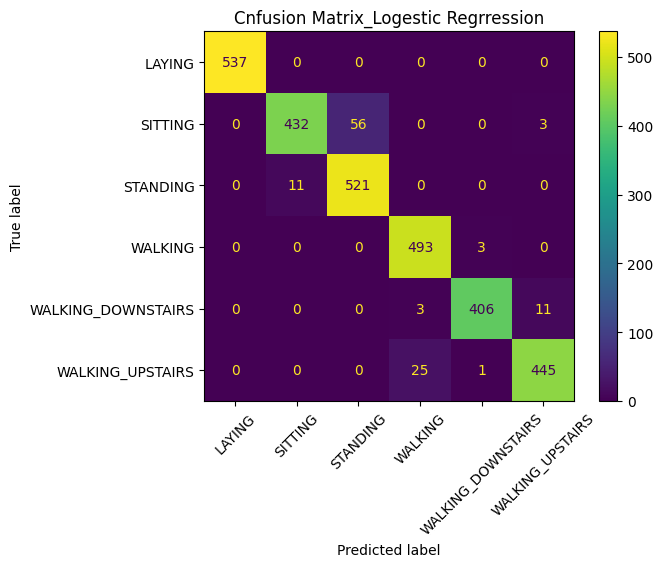

In [65]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.title("Cnfusion Matrix_Logestic Regrression")
plt.xticks(rotation=45)
plt.show()


### Classification Report

We evaluate the baseline model using precision, recall, and F1-score for each activity class.

In [66]:
print(classification_report(y_test,y_pred))

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.98      0.88      0.93       491
          STANDING       0.90      0.98      0.94       532
           WALKING       0.95      0.99      0.97       496
WALKING_DOWNSTAIRS       0.99      0.97      0.98       420
  WALKING_UPSTAIRS       0.97      0.94      0.96       471

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947



## Model Comparison: Random Forest

We train a Random Forest classifier and compare its performance with Logistic Regression.

In [67]:
rf_model=RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train,y_train)
rf_pred=rf_model.predict(x_test)

In [68]:
rf_accuracy=accuracy_score(y_test,rf_pred)
print("Random Forest Accuracy:" , rf_accuracy)

Random Forest Accuracy: 0.9267051238547676


### Model Performance Comparison

We compare Logistic Regression and Random Forest using accuracy, precision, recall, and F1-score.

In [69]:
results=pd.DataFrame({"Model":["Logistic Regression","Random Forest"],
                      "Accuracy":[accuracy_score(y_test,y_pred),accuracy_score(y_test,rf_pred)],
                      "Recall":[recall_score(y_test,y_pred,average="weighted"),recall_score(y_test,rf_pred,average="weighted")],
                      "Precision": [precision_score(y_test, y_pred, average="weighted"),precision_score(y_test, rf_pred, average="weighted")],
                      "F1_score":[f1_score(y_test,y_pred,average="weighted"),f1_score(y_test,rf_pred,average="weighted")
                    ]
                     })
results

,Model,Accuracy,Recall,Precision,F1_score
0,Logistic Regression,0.961656,0.961656,0.963032,0.961512
1,Random Forest,0.926705,0.926705,0.927965,0.926631


## Feature Importance

We identify the features that contribute most to the Logistic Regression model's predictions.

In [70]:
importance=pd.Series(abs(model.coef_).mean(axis=0),index=x_train.columns).sort_values(ascending=False)
importance.head(20)

tBodyGyroJerk-entropy()-X          1.345004
tGravityAcc-mean()-Y               0.941169
tGravityAcc-max()-Y                0.901644
tGravityAcc-min()-Y                0.892611
fBodyGyro-entropy()-X              0.792736
tGravityAcc-energy()-X             0.755987
tBodyAcc-correlation()-X,Y         0.735801
tBodyGyroJerk-arCoeff()-X,2        0.710949
tBodyAccJerk-correlation()-X,Z     0.662424
tBodyAccJerk-entropy()-Z           0.652444
angle(Y,gravityMean)               0.650745
tBodyGyroJerk-correlation()-X,Y    0.640589
tBodyGyroJerk-arCoeff()-X,1        0.628567
angle(X,gravityMean)               0.627154
tGravityAcc-energy()-Y             0.616012
tBodyGyro-correlation()-Y,Z        0.567091
tGravityAcc-mean()-X               0.560287
tBodyGyro-arCoeff()-X,1            0.558891
tGravityAcc-min()-X                0.556591
tGravityAcc-max()-X                0.539488
dtype: float64

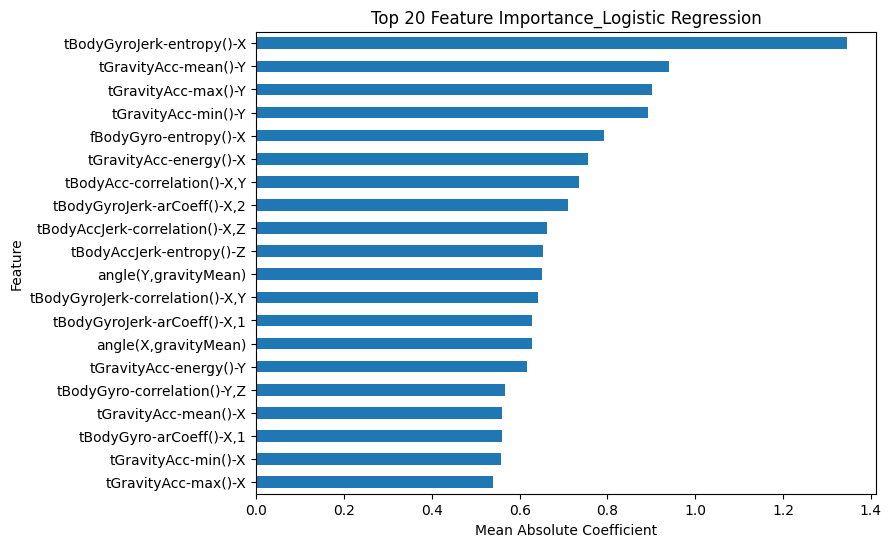

In [71]:
importance.head(20).sort_values().plot(kind="barh",figsize=(8,6))
plt.title("Top 20 Feature Importance_Logistic Regression")
plt.xlabel("Mean Absolute Coefficient")
plt.ylabel("Feature")
plt.show()

### Random Forest Evaluation

We evaluate the Random Forest model using precision, recall, and F1-score.

In [72]:
print(classification_report(y_test,rf_pred))

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.91      0.90      0.90       491
          STANDING       0.91      0.92      0.91       532
           WALKING       0.89      0.97      0.93       496
WALKING_DOWNSTAIRS       0.97      0.87      0.92       420
  WALKING_UPSTAIRS       0.89      0.89      0.89       471

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.93      2947
      weighted avg       0.93      0.93      0.93      2947



### Random Forest Confusion Matrix

The confusion matrix shows the classification errors of the Random Forest model across activity classes.

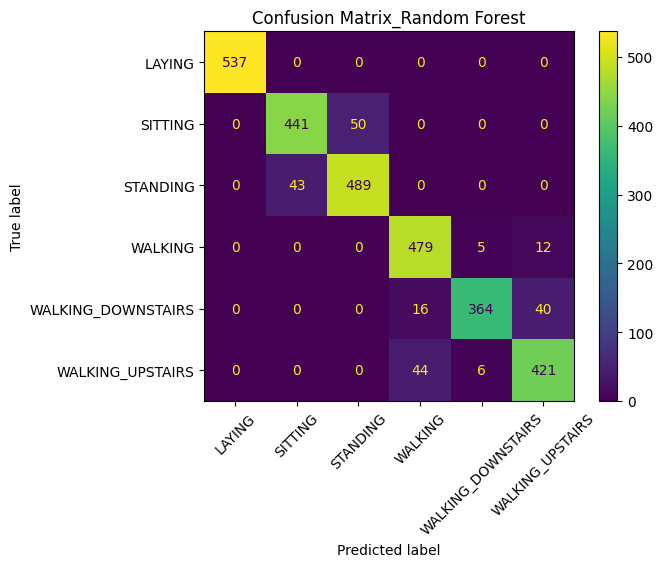

In [73]:
ConfusionMatrixDisplay.from_predictions(y_test,rf_pred)
plt.title("Confusion Matrix_Random Forest")
plt.xticks(rotation=45)
plt.show()

## Cross-Validation

We use 5-fold cross-validation to evaluate the stability of the Logistic Regression model across different subsets of the training data.

In [74]:
cv_scores=cross_val_score(model,x_train,y_train,cv=5,scoring="accuracy")
print("CV scores:",cv_scores)
print("Mean CV accuracy:",cv_scores.mean())
print("Std:", cv_scores.std())

CV scores: [0.92454113 0.89394969 0.94829932 0.95102041 0.96666667]
Mean CV accuracy: 0.9368954434255008
Std: 0.02534898515078111


## Error Analysis

We analyze the most common classification errors to identify activities that are difficult for the model to distinguish.

In [75]:
errors=pd.DataFrame({"True":y_test,"Predicted":y_pred})
errors=errors[errors["True"]!=errors["Predicted"]]
errors.groupby(["True","Predicted"]).size().sort_values(ascending=False)

True                Predicted         
SITTING             STANDING              56
WALKING_UPSTAIRS    WALKING               25
WALKING_DOWNSTAIRS  WALKING_UPSTAIRS      11
STANDING            SITTING               11
WALKING             WALKING_DOWNSTAIRS     3
SITTING             WALKING_UPSTAIRS       3
WALKING_DOWNSTAIRS  WALKING                3
WALKING_UPSTAIRS    WALKING_DOWNSTAIRS     1
dtype: int64

## Subject-Specific Performance

We evaluate model performance separately for each subject to identify differences in activity recognition across individuals.

In [76]:
subject_results = pd.DataFrame({
    "subject": test["subject"],
    "true": y_test,
    "pred": y_pred
})

subject_accuracy = (
    subject_results
    .groupby("subject")
    .apply(lambda x: (x["true"] == x["pred"]).mean())
)

subject_accuracy

/tmp/ipykernel_58/1518930807.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x["true"] == x["pred"]).mean())


subject
2     0.986755
4     0.971609
9     0.892361
10    0.870748
12    0.962500
13    0.993884
18    0.975275
20    0.980226
24    0.997375
dtype: float64

## Personalization Experiment

We investigate whether adapting the model to individual subjects can improve activity recognition performance.

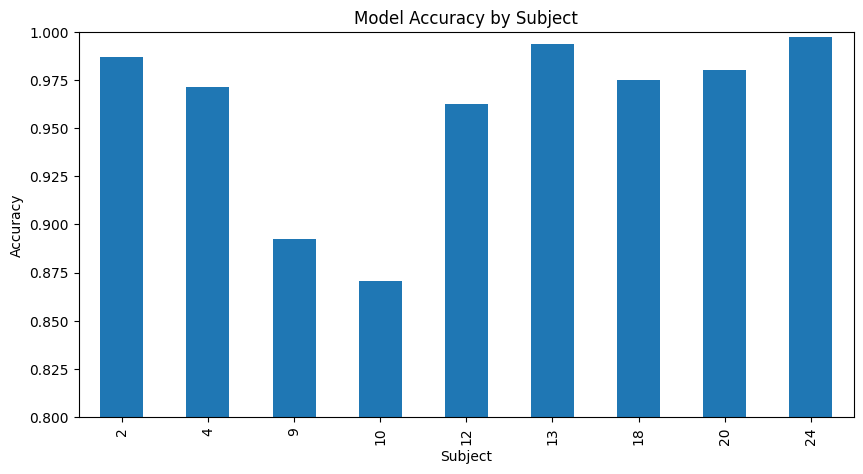

In [77]:
subject_accuracy.plot(kind="bar",figsize=(10,5))
plt.title("Model Accuracy by Subject")
plt.xlabel("Subject")
plt.ylabel("Accuracy")
plt.ylim(0.8,1.0)
plt.show()

In [78]:
subject_id=10
subject_data=test[test["subject"]==subject_id].copy()
print("subject:",subject_id)
print("samples:",subject_data.shape[0])

subject: 10
samples: 294


In [79]:
adapt_data,eval_data=train_test_split(subject_data,test_size=0.5,random_state=42, stratify=subject_data["Activity"])
print("Adaptation Samples:",adapt_data.shape[0])
print("Evaluation Samples:",eval_data.shape[0])

Adaptation Samples: 147
Evaluation Samples: 147


In [80]:
x_eval = eval_data.drop(["Activity", "subject"], axis=1)
y_eval = eval_data["Activity"]

baseline_pred = model.predict(x_eval)

baseline_accuracy = accuracy_score(y_eval, baseline_pred)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.8639455782312925


### Personalization for Subject 10

We adapt the general model using subject-specific data and evaluate its performance on unseen data from the same subject.

In [81]:
x_adapt=adapt_data.drop(["Activity","subject"],axis=1)
y_adapt=adapt_data["Activity"]
x_personal=pd.concat([x_train,x_adapt])
y_personal=pd.concat([y_train,y_adapt])
personal_model=LogisticRegression(max_iter=1000)
personal_model.fit(x_personal,y_personal)
personal_pred=personal_model.predict(x_eval)
personal_accuracy=accuracy_score(y_eval,personal_pred)
print("personalized Accuracy:",personal_accuracy)

personalized Accuracy: 0.9727891156462585


In [82]:
subjects=test["subject"].unique()
print(subjects)

[ 2  4  9 10 12 13 18 20 24]


### General Model

We train a general model using the training data as the baseline for personalization.

In [83]:
general_model = LogisticRegression(max_iter=1000)
general_model.fit(x_train, y_train)

print(
    "General model accuracy:",
    accuracy_score(y_test, general_model.predict(x_test))
)

General model accuracy: 0.9616559212758737


### Personalization Across Subjects

We compare general and personalized model performance across different subjects.

In [84]:
results=[]

for subject_id in subjects:
    subject_data=test[test["subject"]==subject_id].copy()
    adapt_data,eval_data=train_test_split(
        subject_data,
        test_size=0.5,
        random_state=42,
        stratify=subject_data["Activity"]
    )
    
    #Baseline
    x_eval=eval_data.drop(["Activity","subject"],axis=1)
    y_eval=eval_data["Activity"]
    
    baseline_pred=general_model.predict(x_eval)
    baseline_accuracy=accuracy_score(y_eval,baseline_pred)
   
    #Personalizetion
    x_adapt=adapt_data.drop(["Activity","subject"],axis=1)
    y_adapt=adapt_data["Activity"]
   
    x_personal=pd.concat([x_train,x_adapt])
    y_personal=pd.concat([y_train,y_adapt])
    
    personal_model=LogisticRegression(max_iter=1000)
    personal_model.fit(x_personal,y_personal)
   
    personal_pred=personal_model.predict(x_eval)
    personal_accuracy=accuracy_score(y_eval,personal_pred)
    
    results.append({
        "Subject": subject_id,
        "Baseline": baseline_accuracy,
        "Personalized": personal_accuracy,
        "Improvement": personal_accuracy - baseline_accuracy
    })

results_df=pd.DataFrame(results)
print(results_df)

   Subject  Baseline  Personalized  Improvement
0        2  0.980132      0.980132     0.000000
1        4  0.974843      0.974843     0.000000
2        9  0.909722      0.965278     0.055556
3       10  0.863946      0.972789     0.108844
4       12  0.962500      0.975000     0.012500
5       13  1.000000      1.000000     0.000000
6       18  0.967033      0.983516     0.016484
7       20  0.971751      0.988701     0.016949
8       24  1.000000      1.000000     0.000000


### Baseline vs Personalized Performance

We compare the baseline and personalized accuracy for each subject.

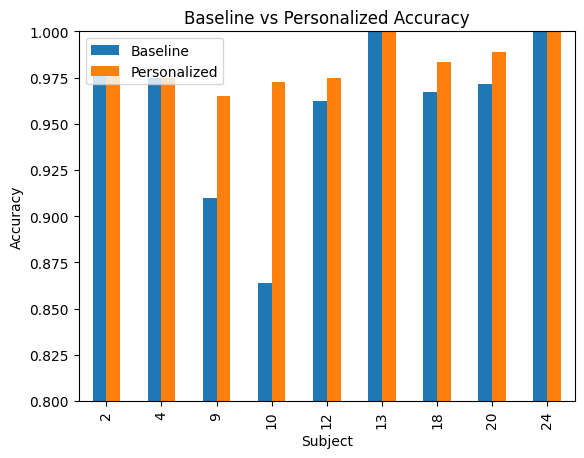

In [85]:
results_df.plot(
    x="Subject",
    y=["Baseline","Personalized"],
    kind="bar"
)

plt.ylabel("Accuracy")
plt.title("Baseline vs Personalized Accuracy")
plt.ylim(0.8,1.0)
plt.show()
    

### Overall Personalization Results

We calculate the mean baseline accuracy, personalized accuracy, and overall improvement across subjects.

In [86]:
mean_baseline = results_df["Baseline"].mean()
mean_personalized = results_df["Personalized"].mean()
mean_improvement = results_df["Improvement"].mean()

print("Mean Baseline:", mean_baseline)
print("Mean Personalized:", mean_personalized)
print("Mean Improvement:", mean_improvement)

Mean Baseline: 0.958880821949176
Mean Personalized: 0.982251017726555
Mean Improvement: 0.023370195777378977


### Statistical Test

We compare baseline and personalized accuracy using the Wilcoxon signed-rank test.

In [87]:
stat, p_value = wilcoxon(
    results_df["Personalized"],
    results_df["Baseline"]
)

print("Wilcoxon statistic:", stat)
print("p-value:", p_value)

Wilcoxon statistic: 0.0
p-value: 0.0625


### Effect of Personalization Data Size

We examine how different amounts of personal data affect model performance.

In [88]:
sample_sizes = [10, 25, 50, 100, 147]

subject_id = 10
subject_data = test[test["subject"] == subject_id].copy()

adapt_data, eval_data = train_test_split(
    subject_data,
    test_size=0.5,
    random_state=42,
    stratify=subject_data["Activity"]
)

X_eval = eval_data.drop(["Activity", "subject"], axis=1)
y_eval = eval_data["Activity"]

for n in sample_sizes:
    X_adapt = adapt_data.drop(["Activity", "subject"], axis=1).iloc[:n]
    y_adapt = adapt_data["Activity"].iloc[:n]

    X_personal = pd.concat([x_train, X_adapt])
    y_personal = pd.concat([y_train, y_adapt])

    personal_model = LogisticRegression(max_iter=1000)
    personal_model.fit(X_personal, y_personal)

    accuracy = accuracy_score(
        y_eval,
        personal_model.predict(X_eval)
    )

    print(n, "samples →", accuracy)

10 samples → 0.8843537414965986
25 samples → 0.9183673469387755
50 samples → 0.9183673469387755
100 samples → 0.9523809523809523
147 samples → 0.9727891156462585


### Personalization Data Size vs Accuracy

We visualize how model accuracy changes as the amount of personalization data increases.

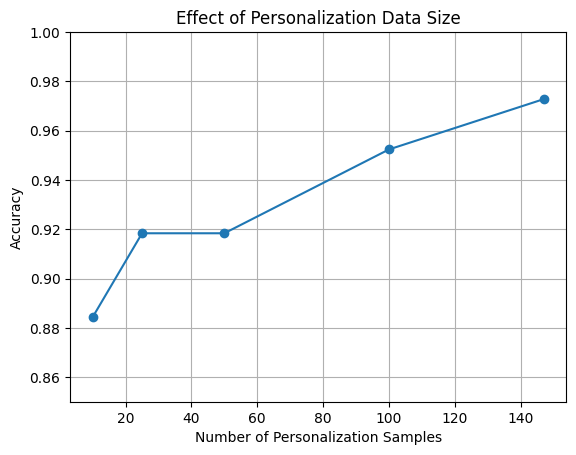

In [89]:
sample_sizes = [10, 25, 50, 100, 147]
accuracies = [
    0.8843537414965986,
    0.9183673469387755,
    0.9183673469387755,
    0.9523809523809523,
    0.9727891156462585
]

plt.plot(sample_sizes, accuracies, marker="o")

plt.xlabel("Number of Personalization Samples")
plt.ylabel("Accuracy")
plt.title("Effect of Personalization Data Size")
plt.ylim(0.85, 1.0)
plt.grid(True)

plt.show()

### Activity-Level Performance

We compare activity recognition performance before and after personalization for each activity.

In [90]:
baseline_pred = general_model.predict(X_eval)
personalized_pred = personal_model.predict(X_eval)

print("Baseline:")
print(classification_report(y_eval, baseline_pred))

print("Personalized:")
print(classification_report(y_eval, personalized_pred))

Baseline:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00        29
           SITTING       0.94      0.56      0.70        27
          STANDING       0.64      0.95      0.76        22
           WALKING       0.81      0.96      0.88        27
WALKING_DOWNSTAIRS       0.95      1.00      0.97        19
  WALKING_UPSTAIRS       1.00      0.74      0.85        23

          accuracy                           0.86       147
         macro avg       0.89      0.87      0.86       147
      weighted avg       0.89      0.86      0.86       147

Personalized:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00        29
           SITTING       0.96      0.89      0.92        27
          STANDING       0.88      0.95      0.91        22
           WALKING       1.00      1.00      1.00        27
WALKING_DOWNSTAIRS       1.00      1.00      1.00        19
  WALKING_UP

### Confusion Matrix: Before vs After Personalization

We compare the confusion matrices before and after personalization to identify which activities were misclassified and how personalization improved the predictions.

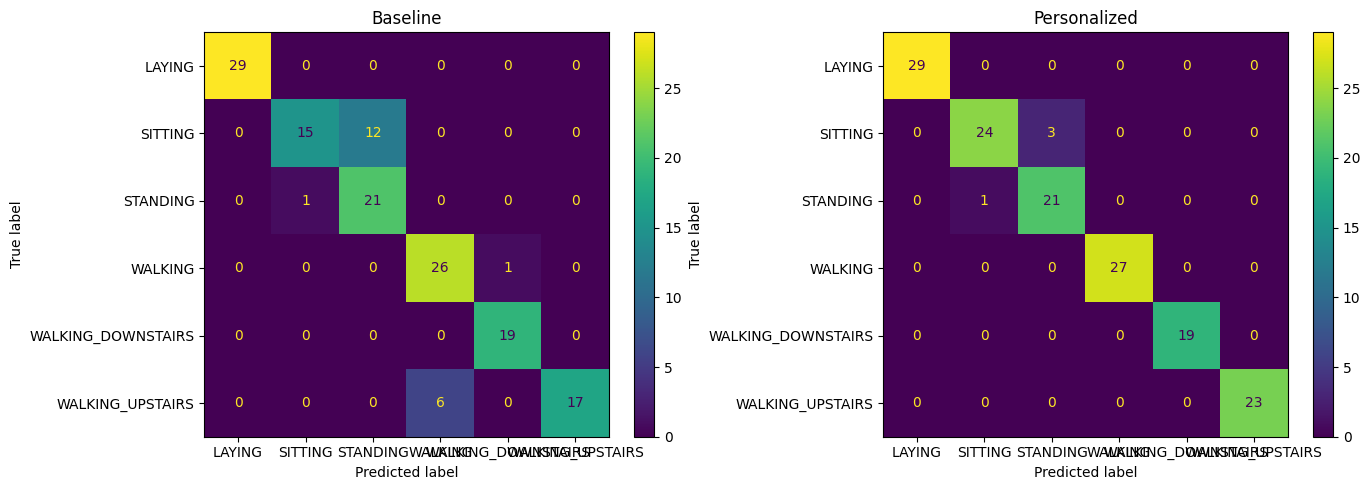

In [91]:
cm_baseline = confusion_matrix(y_eval, baseline_pred)
cm_personalized = confusion_matrix(y_eval, personalized_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    cm_baseline,
    display_labels=general_model.classes_
).plot(ax=axes[0])

axes[0].set_title("Baseline")

ConfusionMatrixDisplay(
    cm_personalized,
    display_labels=personal_model.classes_
).plot(ax=axes[1])

axes[1].set_title("Personalized")

plt.tight_layout()
plt.show()

### Robustness of Personalization Results

We repeat the personalization experiment with different data splits to check whether the results are consistent.

In [92]:
sample_sizes = [10, 25, 50, 100, 147]
random_states = [1, 10, 20, 30, 42]

robustness_results = []

subject_id = 10
subject_data = test[test["subject"] == subject_id].copy()

for random_state in random_states:

    adapt_data, eval_data = train_test_split(
        subject_data,
        test_size=0.5,
        random_state=random_state,
        stratify=subject_data["Activity"]
    )

    X_eval = eval_data.drop(["Activity", "subject"], axis=1)
    y_eval = eval_data["Activity"]

    for n in sample_sizes:

        X_adapt = adapt_data.drop(
            ["Activity", "subject"], axis=1
        ).iloc[:n]

        y_adapt = adapt_data["Activity"].iloc[:n]

        X_personal = pd.concat([x_train, X_adapt])
        y_personal = pd.concat([y_train, y_adapt])

        personal_model = LogisticRegression(max_iter=1000)
        personal_model.fit(X_personal, y_personal)

        accuracy = accuracy_score(
            y_eval,
            personal_model.predict(X_eval)
        )

        robustness_results.append({
            "Random_State": random_state,
            "Samples": n,
            "Accuracy": accuracy
        })

robustness_df = pd.DataFrame(robustness_results)

print(robustness_df)

    Random_State  Samples  Accuracy
0              1       10  0.904762
1              1       25  0.925170
2              1       50  0.945578
3              1      100  0.965986
4              1      147  0.972789
5             10       10  0.918367
6             10       25  0.918367
7             10       50  0.952381
8             10      100  0.972789
9             10      147  0.979592
10            20       10  0.884354
11            20       25  0.904762
12            20       50  0.925170
13            20      100  0.931973
14            20      147  0.952381
15            30       10  0.850340
16            30       25  0.877551
17            30       50  0.897959
18            30      100  0.938776
19            30      147  0.945578
20            42       10  0.884354
21            42       25  0.918367
22            42       50  0.918367
23            42      100  0.952381
24            42      147  0.972789


### Mean and Standard Deviation

We calculate the mean accuracy and standard deviation for each personalization data size across different data splits.

In [93]:
summary = (
    robustness_df
    .groupby("Samples")["Accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

print(summary)

   Samples      mean       std
0       10  0.888435  0.025725
1       25  0.908844  0.018999
2       50  0.927891  0.021832
3      100  0.952381  0.017344
4      147  0.964626  0.014748


### Personalization Performance with Variability

We visualize the mean accuracy and standard deviation for different amounts of personalization data.

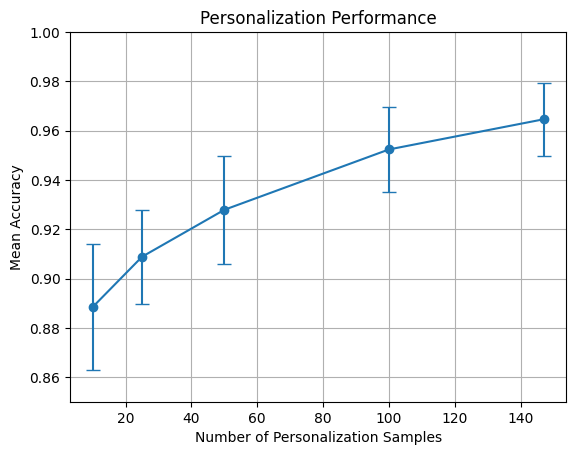

In [94]:
plt.errorbar(
    summary["Samples"],
    summary["mean"],
    yerr=summary["std"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Personalization Samples")
plt.ylabel("Mean Accuracy")
plt.title("Personalization Performance")
plt.ylim(0.85, 1.0)
plt.grid(True)

plt.show()

## Key Results

- Logistic Regression achieved **96.2% accuracy** on the test set.
- Random Forest achieved **92.6% accuracy**.
- Personalization improved the mean accuracy from **95.9% to 98.2%** across subjects.
- For Subject 10, personalization improved accuracy from **86.4% to 97.3%**.
- Increasing personalization data generally improved model performance and stability.

## Conclusion

This project investigated personalized human activity recognition using smartphone sensor data.

A general Logistic Regression model achieved high overall performance, but its performance varied across subjects. Personalization was then performed by adding a small amount of target-subject data to the training set.

For Subject 10, accuracy improved from 86.4% to 97.3% after personalization. Across different personalization data sizes, increasing the amount of subject-specific data generally improved both accuracy and stability.

Overall, the results suggest that personalization can improve activity recognition, especially for subjects whose movement patterns are not well represented by the general model.

## Limitations & Future Work

This study has some limitations. The personalization experiment was performed on a limited number of subjects and used a simple Logistic Regression model. The personalization data was also taken from the test subjects in a simulated adaptation setting.

Future work could investigate more subjects, different personalization strategies, deep learning models, and real-time activity recognition. A more advanced direction would be to develop a context-aware system that uses personalized activity patterns to provide adaptive assistance.